<a href="https://colab.research.google.com/github/Manoj857-cyber/tp53-breast-cancer-survival/blob/main/tp53_survival_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

clinical = pd.read_csv("data_clinical_patient.txt", sep="\t", comment="#")

print(clinical.shape)
clinical.head()

(1084, 38)


,PATIENT_ID,SUBTYPE,CANCER_TYPE_ACRONYM,OTHER_PATIENT_ID,AGE,SEX,AJCC_PATHOLOGIC_TUMOR_STAGE,AJCC_STAGING_EDITION,DAYS_LAST_FOLLOWUP,DAYS_TO_BIRTH,...,IN_PANCANPATHWAYS_FREEZE,OS_STATUS,OS_MONTHS,DSS_STATUS,DSS_MONTHS,DFS_STATUS,DFS_MONTHS,PFS_STATUS,PFS_MONTHS,GENETIC_ANCESTRY_LABEL
0,TCGA-3C-AAAU,BRCA_LumA,BRCA,6E7D5EC6-A469-467C-B748-237353C23416,55,Female,STAGE X,6TH,4047.0,-20211.0,...,Yes,0:LIVING,133.050597,0:ALIVE OR DEAD TUMOR FREE,133.050597,1:Recurred/Progressed,59.440444,1:PROGRESSION,59.440444,EUR
1,TCGA-3C-AALI,BRCA_Her2,BRCA,55262FCB-1B01-4480-B322-36570430C917,50,Female,STAGE IIB,6TH,4005.0,-18538.0,...,Yes,0:LIVING,131.669790,0:ALIVE OR DEAD TUMOR FREE,131.669790,0:DiseaseFree,131.669790,0:CENSORED,131.669790,AFR
2,TCGA-3C-AALJ,BRCA_LumB,BRCA,427D0648-3F77-4FFC-B52C-89855426D647,62,Female,STAGE IIB,7TH,1474.0,-22848.0,...,Yes,0:LIVING,48.459743,0:ALIVE OR DEAD TUMOR FREE,48.459743,0:DiseaseFree,48.459743,0:CENSORED,48.459743,AFR_ADMIX
3,TCGA-3C-AALK,BRCA_LumA,BRCA,C31900A4-5DCD-4022-97AC-638E86E889E4,52,Female,STAGE IA,7TH,1448.0,-19074.0,...,Yes,0:LIVING,47.604958,0:ALIVE OR DEAD TUMOR FREE,47.604958,NaN,NaN,0:CENSORED,47.604958,AFR
4,TCGA-4H-AAAK,BRCA_LumA,BRCA,6623FC5E-00BE-4476-967A-CBD55F676EA6,50,Female,STAGE IIIA,7TH,348.0,-18371.0,...,Yes,0:LIVING,11.440971,0:ALIVE OR DEAD TUMOR FREE,11.440971,0:DiseaseFree,11.440971,0:CENSORED,11.440971,EUR


In [ ]:
mut = pd.read_csv("data_mutations.txt", sep="\t", comment="#", low_memory=False)
print(mut.shape)

tp53 = mut[mut["Hugo_Symbol"] == "TP53"]
tp53_patients = tp53["Tumor_Sample_Barcode"].str[:12].unique()
print(len(tp53_patients))

(126252, 111)
348


In [ ]:
clinical["TP53_mutated"] = clinical["PATIENT_ID"].isin(tp53_patients)

print(clinical["TP53_mutated"].value_counts())

TP53_mutated
False    736
True     348
Name: count, dtype: int64


In [ ]:
clinical["event"] = clinical["OS_STATUS"].str[0].astype(float)

df = clinical.dropna(subset=["OS_MONTHS", "event"]).copy()
df["event"] = df["event"].astype(int)

print(df.shape)
print(df["event"].value_counts())
print(df.groupby("TP53_mutated")["event"].agg(["count", "sum"]))

(1084, 40)
event
0    933
1    151
Name: count, dtype: int64
              count  sum
TP53_mutated            
False           736   99
True            348   52


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


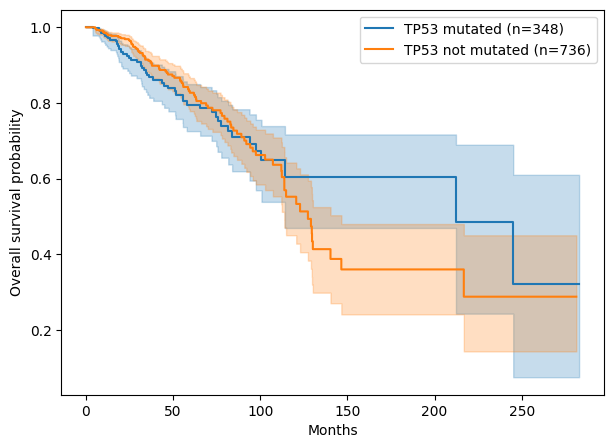

Log-rank p = 0.7531501149132727


In [ ]:
!pip install lifelines -q

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
import matplotlib.pyplot as plt

mut_grp = df[df["TP53_mutated"]]
wt_grp = df[~df["TP53_mutated"]]

kmf = KaplanMeierFitter()
fig, ax = plt.subplots(figsize=(7, 5))

kmf.fit(mut_grp["OS_MONTHS"], mut_grp["event"], label="TP53 mutated (n=348)")
kmf.plot_survival_function(ax=ax)

kmf.fit(wt_grp["OS_MONTHS"], wt_grp["event"], label="TP53 not mutated (n=736)")
kmf.plot_survival_function(ax=ax)

ax.set_xlabel("Months")
ax.set_ylabel("Overall survival probability")
plt.show()

result = logrank_test(
    mut_grp["OS_MONTHS"], wt_grp["OS_MONTHS"],
    event_observed_A=mut_grp["event"], event_observed_B=wt_grp["event"],
)
print("Log-rank p =", result.p_value)

In [ ]:
print(pd.crosstab(df["SUBTYPE"], df["TP53_mutated"]))

TP53_mutated  False  True 
SUBTYPE                   
BRCA_Basal       17    154
BRCA_Her2        23     55
BRCA_LumA       446     53
BRCA_LumB       126     71
BRCA_Normal      25     11


In [ ]:
for sub in ["BRCA_Basal", "BRCA_Her2", "BRCA_LumA", "BRCA_LumB"]:
    s = df[df["SUBTYPE"] == sub]
    a = s[s["TP53_mutated"]]
    b = s[~s["TP53_mutated"]]
    r = logrank_test(a["OS_MONTHS"], b["OS_MONTHS"],
                     event_observed_A=a["event"], event_observed_B=b["event"])
    print(sub, "| mut n =", len(a), "deaths =", a["event"].sum(),
          "| wt n =", len(b), "deaths =", b["event"].sum(),
          "| p =", round(r.p_value, 3))

BRCA_Basal | mut n = 154 deaths = 21 | wt n = 17 deaths = 1 | p = 0.567
BRCA_Her2 | mut n = 55 deaths = 8 | wt n = 23 deaths = 7 | p = 0.016
BRCA_LumA | mut n = 53 deaths = 7 | wt n = 446 deaths = 50 | p = 0.377
BRCA_LumB | mut n = 71 deaths = 12 | wt n = 126 deaths = 19 | p = 0.556


In [ ]:
from lifelines import CoxPHFitter

cox_df = df[["OS_MONTHS", "event", "TP53_mutated", "AGE", "SUBTYPE"]].dropna().copy()
cox_df["TP53_mutated"] = cox_df["TP53_mutated"].astype(int)
cox_df = pd.get_dummies(cox_df, columns=["SUBTYPE"], drop_first=True, dtype=float)

print(len(cox_df))
cph = CoxPHFitter()
cph.fit(cox_df, duration_col="OS_MONTHS", event_col="event")
cph.print_summary()

981


<lifelines.CoxPHFitter: fitted with 981 total observations, 849 right-censored observations>
             duration col = 'OS_MONTHS'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 981
number of events observed = 132
   partial log-likelihood = -714.18
         time fit was run = 2026-11-04 20:03:09 UTC

---
                     coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                            
TP53_mutated         0.14      1.15      0.25           -0.35            0.62                0.71                1.87
AGE                  0.04      1.04      0.01            0.02            0.05                1.02                1.05
SUBTYPE_BRCA_Her2    0.72      2.06      0.34            0.06            1.38                1.06                3.99
SUBTYPE_BRCA_LumA   -0.10      0.91      0.33           -0.74            0.55                0.48                1.73
SUBTYPE_BRCA_LumB    0.43      1.54      0.32           -0.19            1.05                0.82                2.86
SUBTYPE_BRCA_Normal  0.49      1.63      0.46           -0.42            1.40                0.66                4.04

                     cmp to     z      p  -log2(p)
covariate                                         
TP53_mutated           0.00  0.56   0.58      0.80
AGE                    0.00  5.15 <0.005     21.84
SUBTYPE_BRCA_Her2      0.00  2.13   0.03      4.90
SUBTYPE_BRCA_LumA      0.00 -0.30   0.76      0.39
SUBTYPE_BRCA_LumB      0.00  1.35   0.18      2.50
SUBTYPE_BRCA_Normal    0.00  1.05   0.29      1.77
---
Concordance = 0.67
Partial AIC = 1440.36
log-likelihood ratio test = 36.73 on 6 df
-log2(p) of ll-ratio test = 18.94